# Coupled Rayleigh grids

A fixed phase frame at the band centre couples successive grids.
Reference and loaded states reuse each Rayleigh sample. The finest grid is
a numerical reference; its zero error against itself does not prove convergence.
Install PyRayleigh, NumPy and Matplotlib.

In [1]:
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from pyrayleigh import (Fiber, FiberState, Field, FieldTerm, GuideOptics, Probe,
    Section, SpatialProfile, compute_response_diagnostics, refine_rayleigh_from_normals)
from pyrayleigh.constants import SPEED_OF_LIGHT

seed, refinement_seed, levels = 123, 124, 6

In [2]:
def coupled_grids(*, seed=123, refinement_seed=124, levels=6):
    if levels < 2:
        raise ValueError('at least two grid levels are required')
    frequency = SPEED_OF_LIGHT/1550e-9
    length = .08
    guide = GuideOptics(frequency, 1.47, 1.47)
    fiber = Fiber('coupled', length, 293.15, frequency-5e9, frequency+5e9,
        (Section(0., length, guide, 0., .1),))
    fiber = fiber.with_rayleigh(seed, cell_length=.01)
    fibers = [fiber]
    rng = np.random.Generator(np.random.PCG64(refinement_seed))
    for _ in range(levels-1):
        parent = fibers[-1]
        normals = rng.standard_normal((parent.rayleigh.cell_count, 2))
        sample = refine_rayleigh_from_normals(parent, normals,
            reference_frequency=frequency)
        fibers.append(replace(parent, rayleigh=sample))
    return fibers


def relative_error(value, reference):
    scale = np.linalg.norm(reference)
    if scale == 0.:
        return np.nan
    return float(np.linalg.norm(value-reference)/scale)


def run(*, seed=123, refinement_seed=124, levels=6):
    fibers = coupled_grids(seed=seed, refinement_seed=refinement_seed, levels=levels)
    probe = Probe(np.linspace(fibers[0].frequency_min, fibers[0].frequency_max, 129))
    strain = SpatialProfile([.027, .028, .039, .040], [0., 1e-5, 1e-5, 0.])
    state = FiberState(axial_strain=Field((FieldTerm(strain),)))
    unloaded, loaded = [], []
    for fiber in fibers:
        unloaded.append(compute_response_diagnostics(fiber, probe,
            loss_convention='background'))
        loaded.append(compute_response_diagnostics(fiber, probe, state,
            loss_convention='background'))
    return fibers, probe, unloaded, loaded

In [3]:
fibers, probe, unloaded, loaded = run(seed=seed, refinement_seed=refinement_seed, levels=levels)
cells = np.array([fiber.rayleigh.cell_count for fiber in fibers])
delta = [b.total.reflection-a.total.reflection for a, b in zip(unloaded, loaded)]
print('One frozen realization, 10 GHz band, zero background attenuation.')
print('cells   reference r error   loaded r error   strain-induced field error')
for fiber, before, after, change in zip(fibers, unloaded, loaded, delta):
    print(f'{fiber.rayleigh.cell_count:5d}   '
          f'{relative_error(before.total.reflection, unloaded[-1].total.reflection):.6e}   '
          f'{relative_error(after.total.reflection, loaded[-1].total.reflection):.6e}   '
          f'{relative_error(change, delta[-1]):.6e}')

One frozen realization, 10 GHz band, zero background attenuation.
cells   reference r error   loaded r error   strain-induced field error
    8   7.768103e-01   7.673906e-01   9.953995e-01
   16   3.883142e-01   3.213656e-01   4.409514e-01
   32   2.266795e-01   2.081146e-01   1.950334e-01
   64   9.672631e-02   9.313078e-02   8.181553e-02
  128   4.792842e-02   4.683649e-02   3.970252e-02
  256   0.000000e+00   0.000000e+00   0.000000e+00


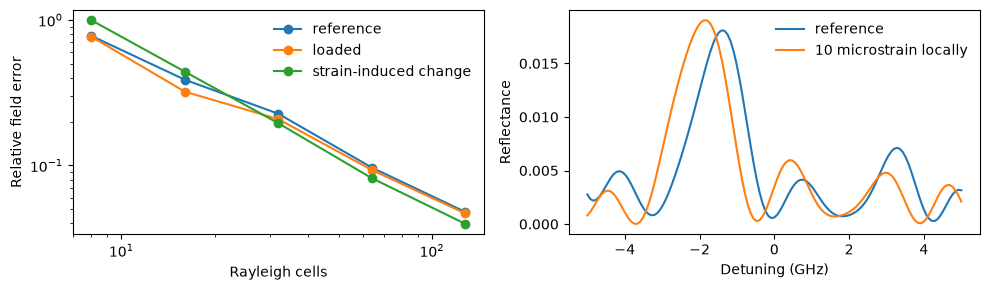

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for name, results in (('reference', unloaded), ('loaded', loaded)):
    errors = [relative_error(result.total.reflection, results[-1].total.reflection)
        for result in results[:-1]]
    ax[0].loglog(cells[:-1], errors, 'o-', label=name)
ax[0].loglog(cells[:-1], [relative_error(value, delta[-1]) for value in delta[:-1]],
    'o-', label='strain-induced change')
ax[0].set(xlabel='Rayleigh cells', ylabel='Relative field error')
detuning = (np.asarray(probe.frequency)-SPEED_OF_LIGHT/1550e-9)/1e9
ax[1].plot(detuning, abs(unloaded[-1].total.reflection)**2, label='reference')
ax[1].plot(detuning, abs(loaded[-1].total.reflection)**2, label='10 microstrain locally')
ax[1].set(xlabel='Detuning (GHz)', ylabel='Reflectance')
for axis in ax:
    axis.legend(frameon=False)
fig.tight_layout()
plt.show()

## Several realizations

RMS errors pool the field norms over realizations. The p90 is descriptive,
not a confidence bound. Adjacent-grid increments help check the finest reference.

In [5]:
def run_ensemble(*, samples=16, levels=7, seed=124):
    if samples < 2 or levels < 2:
        raise ValueError('at least two samples and two grid levels are required')
    fields = []
    for stream in np.random.SeedSequence(seed).spawn(samples):
        initial_seed, bridge_seed = stream.generate_state(2, dtype=np.uint64)
        fibers, _, unloaded, loaded = run(seed=int(initial_seed),
            refinement_seed=int(bridge_seed), levels=levels)
        before = np.stack([result.total.reflection for result in unloaded])
        after = np.stack([result.total.reflection for result in loaded])
        fields.append(np.stack((before, after, after-before)))
    cells = np.array([fiber.rayleigh.cell_count for fiber in fibers])
    return cells, np.stack(fields)


def field_errors(fields):
    """fields has shape (samples, levels, frequencies), without phase fitting."""
    reference = fields[:, -1, :]
    norms = np.linalg.norm(reference, axis=-1)
    if np.any(norms == 0.) or not np.all(np.isfinite(norms)):
        raise ValueError('reference fields must have finite, nonzero norms')
    errors = np.linalg.norm(fields-reference[:, None, :], axis=-1)
    changes = np.linalg.norm(np.diff(fields, axis=1), axis=-1)
    scale = np.linalg.norm(norms)
    rms = np.linalg.norm(errors, axis=0)/scale
    p90 = np.quantile(errors/norms[:, None], .9, axis=0)
    increments = np.linalg.norm(changes, axis=0)/scale
    return rms, p90, increments

In [6]:
samples, ensemble_levels, ensemble_seed = 16, 7, 124
ensemble_cells, fields = run_ensemble(samples=samples, levels=ensemble_levels, seed=ensemble_seed)
ensemble_reports = [field_errors(data) for data in np.moveaxis(fields, 1, 0)]
print(f'{samples} realizations, {ensemble_levels} levels, root seed {ensemble_seed}.')
print('Last adjacent-grid increments (reference, loaded, strain-induced change):')
print([float(report[2][-1]) for report in ensemble_reports])

16 realizations, 7 levels, root seed 124.
Last adjacent-grid increments (reference, loaded, strain-induced change):
[0.022485828742018592, 0.022049326866239824, 0.023012995581400283]


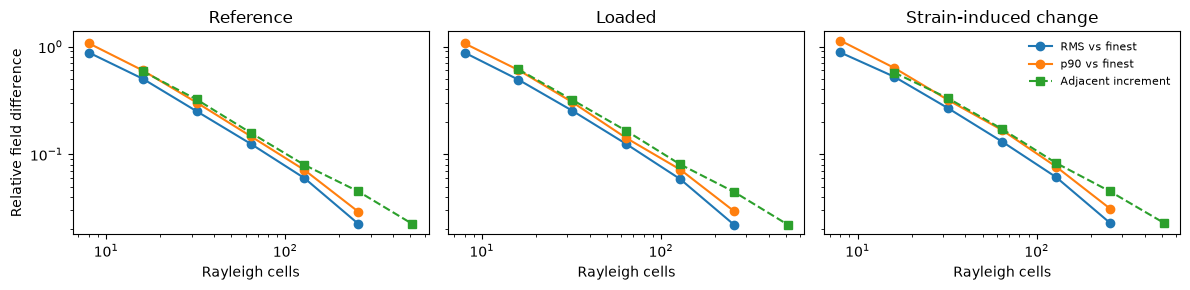

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for axis, name, report in zip(ax, ('Reference', 'Loaded', 'Strain-induced change'), ensemble_reports):
    rms, p90, increments = report
    axis.loglog(ensemble_cells[:-1], rms[:-1], 'o-', label='RMS vs finest')
    axis.loglog(ensemble_cells[:-1], p90[:-1], 'o-', label='p90 vs finest')
    axis.loglog(ensemble_cells[1:], increments, 's--', label='Adjacent increment')
    axis.set(title=name, xlabel='Rayleigh cells')
ax[0].set_ylabel('Relative field difference')
ax[-1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()